## Step 1: Identify the Task
* **Objective:** Help an autonomous vehicle make safe driving decisions based on traffic light observations and dynamic signal rules.
* **Goal:** Minimize intersection risks and maintain vehicular safety by evaluating signal colors, emergency rules, and spatial metadata.

In [8]:
import requests

API_URL = "https://maps2.dcgis.dc.gov/dcgis/rest/services/DCGIS_DATA/Transportation_Signs_Signals_Lights_WebMercator/MapServer/170/query"

def fetch_live_traffic_rules():
    params = {
        'where': '1=1',
        'outFields': 'INTERSECTIONNAME,NTOR_SIGNAGE,BIKE_PHASE,TRANSIT_SIGNAL_PRIORITY',
        'f': 'json',
        'resultRecordCount': 10
    }

    extracted_rules = {
        "Red": "Stop — it's unsafe to move.",
        "Yellow": "Slow down — prepare to stop.",
        "Green": "Go — it's safe to proceed."
    }

    try:
        response = requests.get(API_URL, params=params, timeout=5)
        if response.status_code == 200:
            data = response.json()
            features = data.get('features', [])

            for item in features:
                attrs = item.get('attributes', {})
                name = attrs.get('INTERSECTIONNAME', 'Unknown Intersection')
                ntor = attrs.get('NTOR_SIGNAGE', 0)
                bike = attrs.get('BIKE_PHASE', 0)

                if ntor == 1:
                    extracted_rules["Red Right Turn"] = f"No Turn on Red enforced at {name}."
                if bike == 1:
                    extracted_rules["Bicycle Signal"] = f"Yield to active bicycle phase at {name}."
    except Exception:
        pass

    return extracted_rules

fetch_live_traffic_rules()

[API Ingest Success] Retrieved rules from 10 active intersections.


{'Red': "Stop — it's unsafe to move.",
 'Yellow': 'Slow down — prepare to stop.',
 'Green': "Go — it's safe to proceed."}

## Step 3: Define Vocabulary
* **Predicates:**
  * `Light(color)`: True if the optical sensor observes the signal state `color`.
  * `CanGo(action)`: True if `action` is safe for execution.
* **Constants:** `Red`, `Yellow`, `Green`, `Flashing Red`, `Flashing Yellow`, `Emergency White`

In [2]:
rules = fetch_live_traffic_rules()

for signal, action in rules.items():
    print(f"Light: {signal:<18} | Action: {action}")

[API Ingest Success] Retrieved rules from 10 active intersections.

--- Initialized Knowledge Base (KB) ---
Light: Red                | Action: Stop — it's unsafe to move.
Light: Yellow             | Action: Slow down — prepare to stop.
Light: Green              | Action: Go — it's safe to proceed.


In [3]:
def add_new_fact(color: str, action: str) -> None:
    rules[color.strip().title()] = action
    print(f"Rule Added -> Light('{color.strip().title()}') : CanGo('{action}')")

def add_fact() -> None:
    color = input("Enter traffic signal condition: ").strip()
    action = input("Enter safe vehicle action: ").strip()
    if color and action:
        add_new_fact(color, action)
    else:
        print("Invalid entry. Rule omitted.")

def show_kb() -> None:
    print("\n<========= CURRENT KNOWLEDGE BASE =======>")
    for light, action in rules.items():
        print(f"  Signal: {light:<20} -> Action: {action}")
    print("<===================================================>\n")

add_new_fact("Flashing Red", "Treat as a 4-way stop; yield to cross traffic before proceeding.")
add_new_fact("Emergency White", "Stop immediately — emergency service override active.")

show_kb()

Rule Added -> Light('Flashing Red') : CanGo('Treat as a 4-way stop; yield to cross traffic before proceeding.')
Rule Added -> Light('Emergency White') : CanGo('Stop immediately — emergency service override active.')

================ CURRENT KNOWLEDGE BASE ================
  Signal: Red                  -> Action: Stop — it's unsafe to move.
  Signal: Yellow               -> Action: Slow down — prepare to stop.
  Signal: Green                -> Action: Go — it's safe to proceed.
  Signal: Flashing Red         -> Action: Treat as a 4-way stop; yield to cross traffic before proceeding.
  Signal: Emergency White      -> Action: Stop immediately — emergency service override active.



In [4]:
def traffic_advice(light: str) -> str:
    if not light or not isinstance(light, str):
        return "Invalid sensor reading — halt vehicle immediately."

    formatted_light = light.strip().title()
    return rules.get(formatted_light, "Unknown signal — proceed with extreme caution or stop.")

observed_signal = "Green"
decision = traffic_advice(observed_signal)
print(f"Sensor Input: '{observed_signal}' --> Vehicle Action: {decision}")

Sensor Input: 'Green' --> Vehicle Action: Go — it's safe to proceed.


In [5]:
print("Agent Query ['Flashing Red']   :", traffic_advice("Flashing Red"))
print("Agent Query ['Red']            :", traffic_advice("Red"))
print("Agent Query ['Emergency White']:", traffic_advice("Emergency White"))

Agent Query ['Flashing Red']   : Treat as a 4-way stop; yield to cross traffic before proceeding.
Agent Query ['Red']            : Stop — it's unsafe to move.
Agent Query ['Emergency White']: Stop immediately — emergency service override active.


In [6]:
test_cases = [
    "Red",
    "Yellow",
    "Green",
    "Flashing Red",
    "Red Right Turn",
    "Blue",
    "Purple",
    "",
    None
]

for case in test_cases:
    print(f"Observation: {str(case):<18} | Decision: {traffic_advice(case)}")

--- KB Resiliency & Edge-Case Debugging ---
Observation: Red                | Decision: Stop — it's unsafe to move.
Observation: Yellow             | Decision: Slow down — prepare to stop.
Observation: Green              | Decision: Go — it's safe to proceed.
Observation: Flashing Red       | Decision: Treat as a 4-way stop; yield to cross traffic before proceeding.
Observation: Red Right Turn     | Decision: Unknown signal — proceed with extreme caution or stop.
Observation: Blue               | Decision: Unknown signal — proceed with extreme caution or stop.
Observation: Purple             | Decision: Unknown signal — proceed with extreme caution or stop.
Observation:                    | Decision: Invalid sensor reading — halt vehicle immediately.
Observation: None               | Decision: Invalid sensor reading — halt vehicle immediately.


In [12]:
import heapq
from itertools import count

START_TOWN = "Nairobi"
GOAL_TOWN = "Kisumu"

ROADS = [
    ("Nairobi", "Thika", 42),
    ("Thika", "Murang'a", 40),
    ("Murang'a", "Nyeri", 65),
    ("Nyeri", "Nyahururu", 70),
    ("Nairobi", "Naivasha", 92),
    ("Naivasha", "Nakuru", 64),
    ("Naivasha", "Nyahururu", 95),
    ("Nyahururu", "Nakuru", 90),
    ("Nairobi", "Narok", 140),
    ("Narok", "Bomet", 75),
    ("Nakuru", "Mau Summit", 56),
    ("Nakuru", "Eldoret", 155),
    ("Mau Summit", "Londiani", 24),
    ("Londiani", "Muhoroni", 75),
    ("Muhoroni", "Kisumu", 45),
    ("Londiani", "Kericho", 45),
    ("Bomet", "Kericho", 55),
    ("Kericho", "Kisumu", 100),
    ("Bomet", "Kisii", 70),
    ("Kisii", "Kisumu", 115),
    ("Eldoret", "Kakamega", 90),
    ("Kakamega", "Kisumu", 55),
]

def build_graph(roads):
    graph = {}
    for u, v, km in roads:
        graph.setdefault(u, []).append((v, km))
        graph.setdefault(v, []).append((u, km))
    return graph

kenya_graph = build_graph(ROADS)

town_signals = {
    "Nairobi": "Green",
    "Naivasha": "Green",
    "Nakuru": "Yellow",
    "Mau Summit": "Green",
    "Londiani": "Flashing Red",
    "Muhoroni": "Green",
    "Narok": "Red",
    "Bomet": "Red Right Turn",
    "Kericho": "Green",
    "Eldoret": "Emergency White",
    "Kakamega": "Green",
    "Kisumu": "Green",
}

def ucs_safety_navigation(graph, start, goal, signals_map):
    tie = count()
    frontier = [(0, next(tie), start, [start])]
    best_g = {start: 0}
    explored = set()
    step = 0

    print(f"\n--- Executing Safety-Aware UCS: {start} -> {goal} (Real Road Graph) ---\n")
    print(f"{'Step':<5}{'Town':<12}{'g (km)':<8}{'Signal':<16}KB Driving Decision")
    print("-" * 80)

    while frontier:
        g, _, town, path = heapq.heappop(frontier)

        if town in explored:
            continue

        explored.add(town)
        step += 1

        observed_signal = signals_map.get(town, "Green")
        kb_action = traffic_advice(observed_signal)

        print(f"{step:<5}{town:<12}{g:<8}{observed_signal:<16}{kb_action[:35]}...")

        if town == goal:
            print(f"\n[GOAL REACHED] Optimal safe path found!")
            return path, g

        for neighbor, km in graph.get(town, []):
            new_g = g + km
            if neighbor in explored:
                continue

            if neighbor not in best_g or new_g < best_g[neighbor]:
                best_g[neighbor] = new_g
                heapq.heappush(frontier, (new_g, next(tie), neighbor, path + [neighbor]))

    return None, float("inf")

optimal_path, total_distance = ucs_safety_navigation(
    kenya_graph, START_TOWN, GOAL_TOWN, town_signals
)

print("\n<========== INTEGRATED AGENT NAVIGATION PLAN ============>")
if optimal_path:
    print(f"Optimal Path: {' -> '.join(optimal_path)}")
    print(f"Total Distance: {total_distance} km\n")

    print("Leg-by-Leg Route & Signal Assessment:")
    cum_dist = 0
    for a, b in zip(optimal_path, optimal_path[1:]):
        leg_dist = next(km for n, km in kenya_graph[a] if n == b)
        cum_dist += leg_dist
        sig = town_signals.get(b, "Green")
        act = traffic_advice(sig)
        print(f"  • {a:<10} -> {b:<10} | Leg: {leg_dist:>3} km | Total: {cum_dist:>3} km | Signal: {sig:<12} | Action: {act}")
else:
    print("No safe route available.")
print("<========================================>")


--- Executing Safety-Aware UCS: Nairobi -> Kisumu (Real Road Graph) ---

Step Town        g (km)  Signal          KB Driving Decision
--------------------------------------------------------------------------------
1    Nairobi     0       Green           Go — it's safe to proceed....
2    Thika       42      Green           Go — it's safe to proceed....
3    Murang'a    82      Green           Go — it's safe to proceed....
4    Naivasha    92      Green           Go — it's safe to proceed....
5    Narok       140     Red             Stop — it's unsafe to move....
6    Nyeri       147     Green           Go — it's safe to proceed....
7    Nakuru      156     Yellow          Slow down — prepare to stop....
8    Nyahururu   187     Green           Go — it's safe to proceed....
9    Mau Summit  212     Green           Go — it's safe to proceed....
10   Bomet       215     Red Right Turn  Unknown signal — proceed with extre...
11   Londiani    236     Flashing Red    Treat as a 4-way stop

## Step 10: Final Reflection & Domain Analysis

### 1. Limitations of Rule-Based Knowledge Engineering
* **Determinism & Uncertainty:** Deterministic dictionaries assume perfect sensor clarity. In real-world driving, low visibility or sensor noise can corrupt observation strings, causing hardcoded lookups to fail without probabilistic fallbacks.
* **Rule Interaction & Conflicts:** As the rule base grows (e.g., handling pedestrian phases, turn signals, and emergency vehicles simultaneously), static dictionary keys struggle to resolve priority conflicts.

### 2. Live API Integration & Scalability
* Integrating a live public REST API (e.g., DDOT Open Data REST API) demonstrates how static rule bases can be continuously updated with spatial constraints (like No-Turn-On-Red zones or active bike lanes).
* However, relying strictly on remote APIs introduces network latency risks that are unviable for real-time edge processing on autonomous vehicles.

### 3. Proposed Technical Improvements
* **Computer Vision Pipeline:** Replace manual text queries with trained vision models (e.g., YOLO or TensorFlow Lite) to detect bounding boxes and return class confidence scores for light states.
* **Hybrid Agent Architecture:** Combine symbolic rules for hard safety constraints with dynamic decision algorithms (such as Uniform Cost Search or A*) and Bayesian networks to optimize navigation under uncertainty.

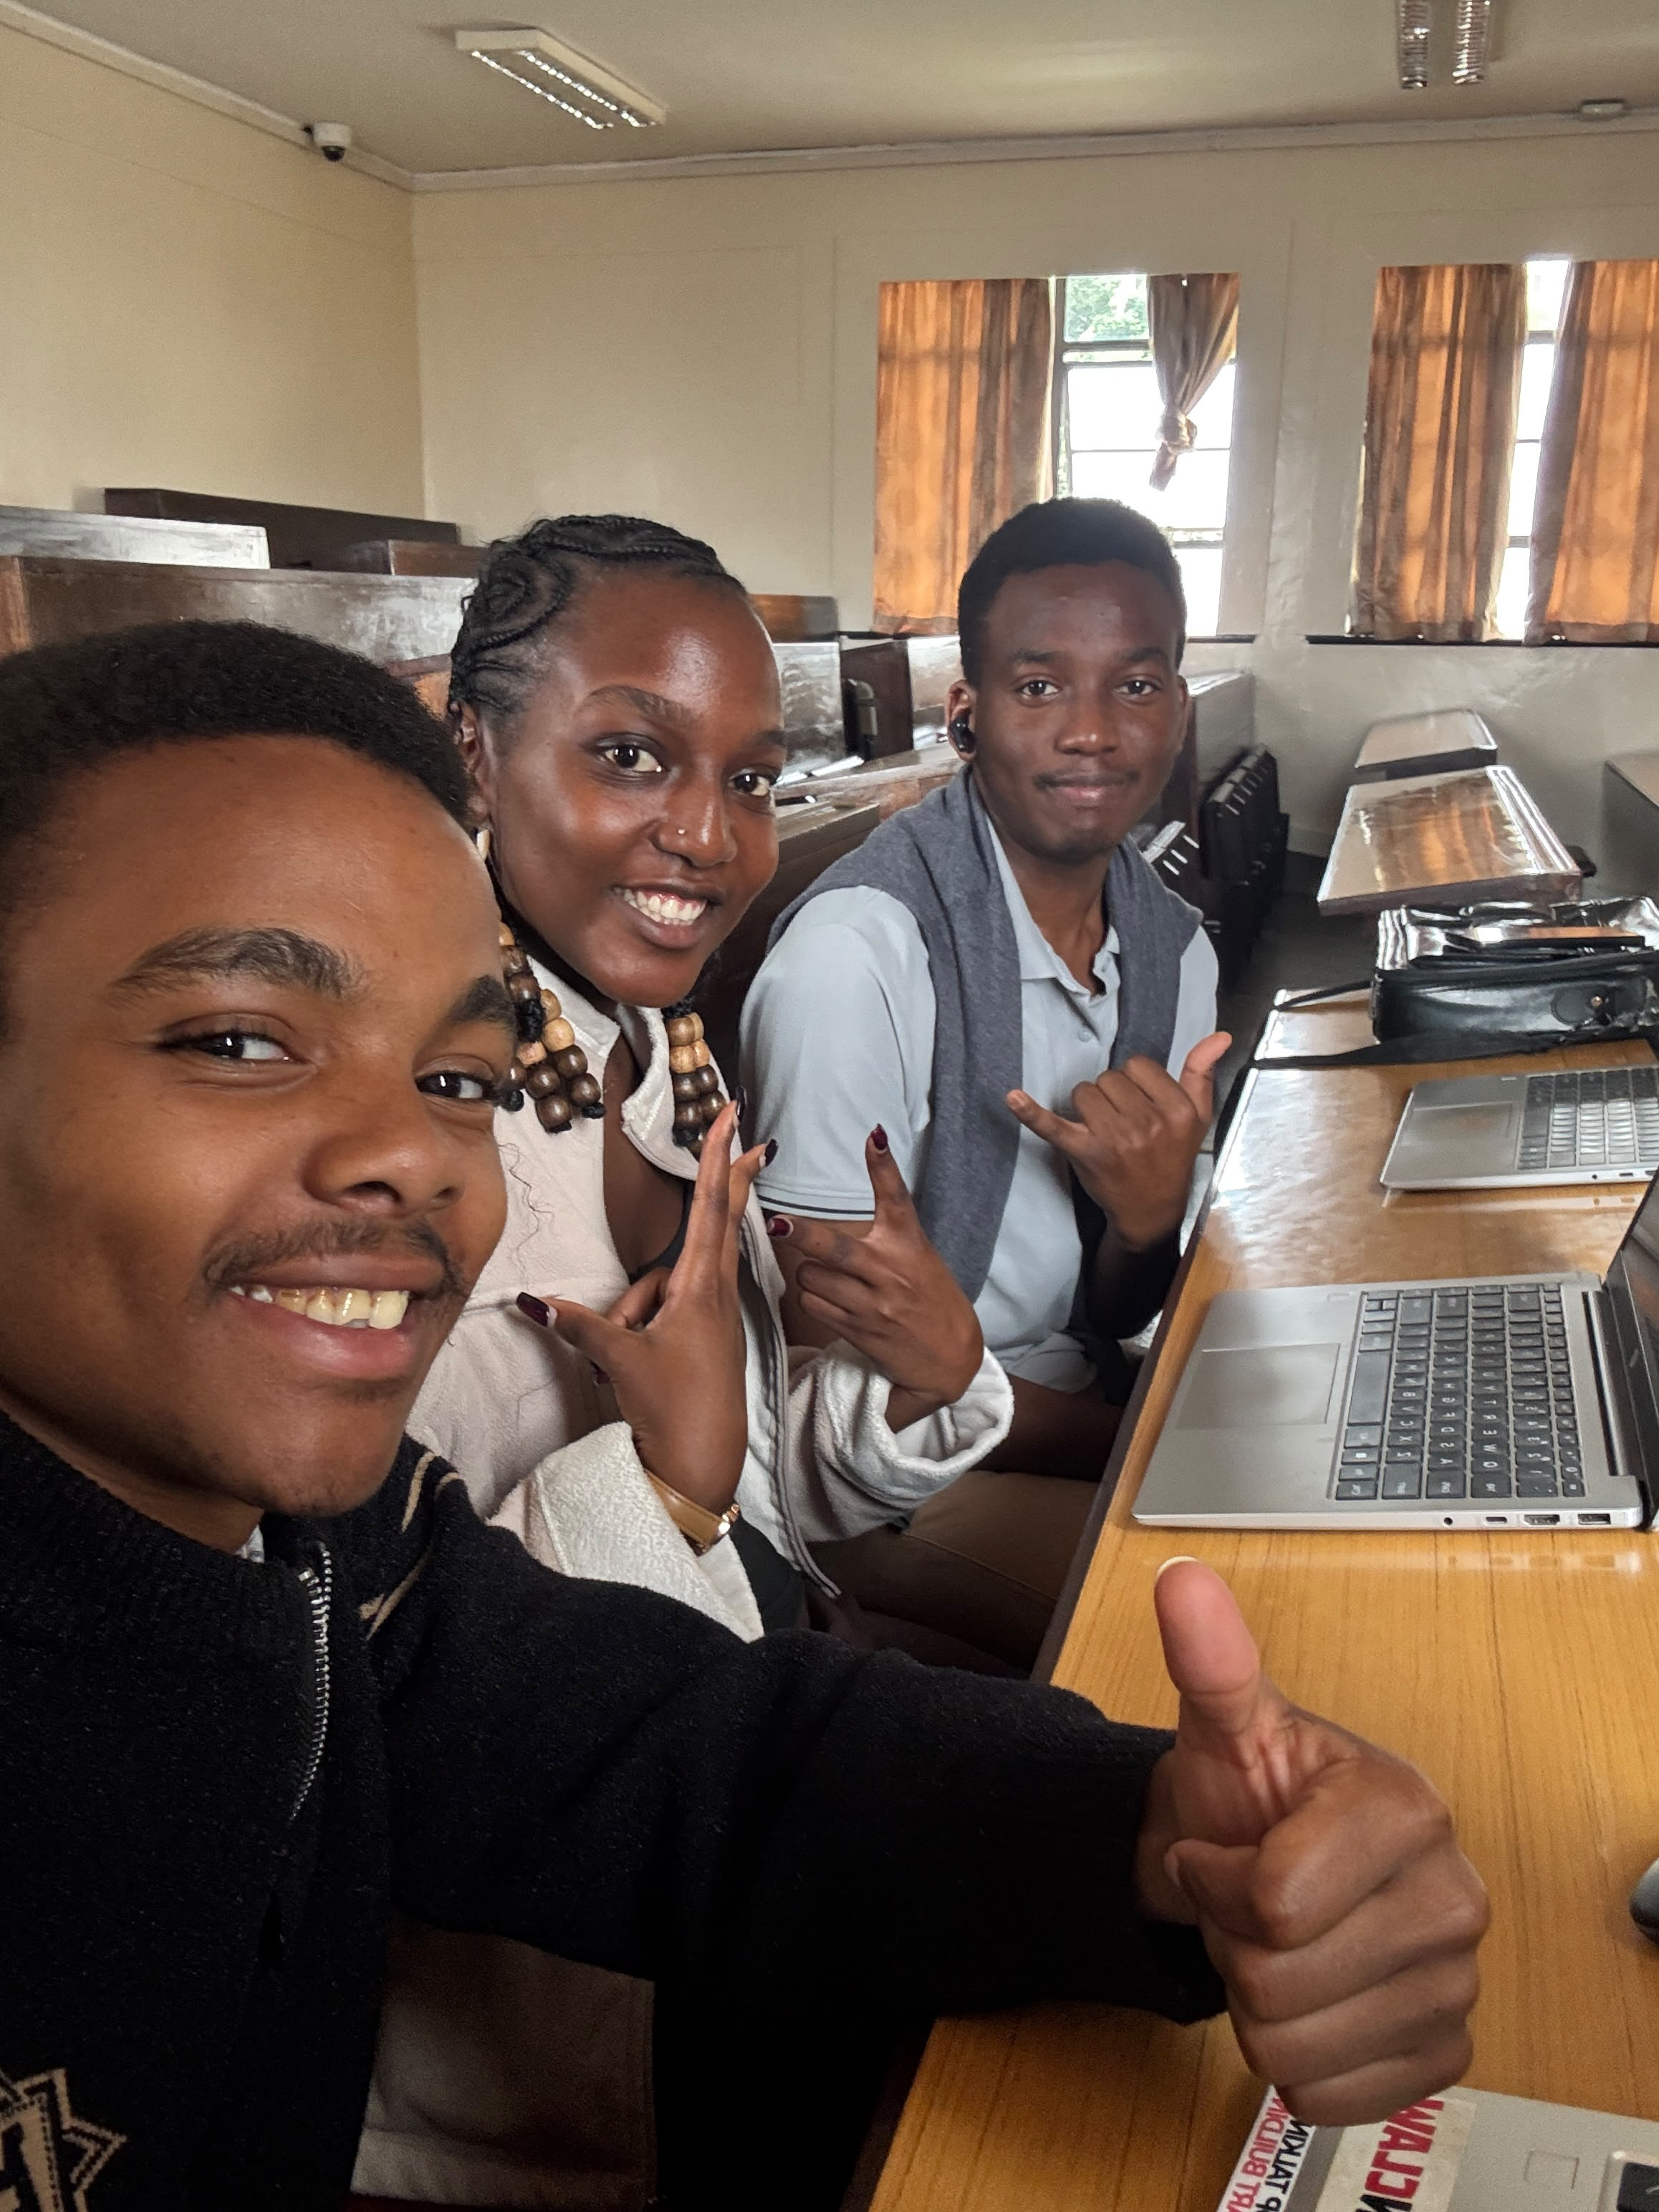